# Laboratorio 23: clasificación de dígitos con redes neuronales
### Dataset MNIST · TensorFlow y Keras
**Universidad Cooperativa de Colombia · Analítica de Datos**  
**Docente:** Luis Miguel Gómez Meneses

**Objetivo:** entrenar una red neuronal para reconocer dígitos escritos a mano, interpretar sus predicciones y observar cómo los hiperparámetros influyen en el subajuste y el sobreajuste.

Trabajaremos con imágenes reales de los números del **0 al 9**. Primero entrenaremos un modelo de referencia; después construiremos ejemplos de subajuste y sobreajuste y probaremos una forma de reducir este último.

Ejecuta las celdas en orden y responde las preguntas en los espacios de Markdown. **El notebook se puede abrir en Google Colab o Jupyter.** La primera carga de MNIST necesita conexión a internet. Puedes usar CPU; una GPU es opcional. Los tiempos dependen del equipo.

## 1. Importar las librerías

**TensorFlow** es la herramienta con la que diseñaremos y entrenaremos las redes. Usaremos **Keras**, su interfaz de alto nivel mediante `tf.keras`, para construir las capas y ejecutar el entrenamiento.

- **NumPy:** trabajar con imágenes y probabilidades.
- **Pandas:** organizar los resultados en tablas.
- **Matplotlib:** visualizar imágenes, curvas y predicciones.
- **Scikit-learn:** separar los datos y construir la matriz de confusión.

En Colab normalmente están disponibles. Si trabajas en Jupyter y falta alguna, descomenta y ejecuta la siguiente línea; después reinicia el kernel y continúa desde las importaciones.

In [ ]:
%pip install tensorflow numpy pandas matplotlib scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from IPython.display import display

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

print("TensorFlow:", tf.__version__)
print("GPU disponible:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU disponible: False


## 2. Cargar el dataset MNIST

MNIST contiene **70 000 imágenes en escala de grises**, de **28 × 28 píxeles**, distribuidas originalmente en 60 000 imágenes para entrenamiento y 10 000 para prueba.

| Elemento | Significado |
|---|---|
| **X** | Imagen del dígito: una matriz de 28 × 28 intensidades. |
| **y** | Etiqueta real: un entero entre 0 y 9. |
| Píxel | Intensidad entre 0 (negro) y 255 (blanco). |
| Clase | Uno de los diez dígitos que queremos reconocer. |

**Es una clasificación multiclase.** Aunque las etiquetas sean números, representan categorías: predecir 8 cuando la etiqueta es 3 es una clasificación incorrecta, no un error de regresión de cinco unidades.

In [2]:
(X_desarrollo_original, y_desarrollo), (X_prueba_original, y_prueba) = (
    keras.datasets.mnist.load_data()
)

print("Imágenes de desarrollo:", X_desarrollo_original.shape)
print("Imágenes de prueba:", X_prueba_original.shape)
print("Etiquetas de desarrollo:", y_desarrollo.shape)
print("Clases:", np.unique(y_desarrollo))
print("Intensidades:", X_desarrollo_original.min(), "a", X_desarrollo_original.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Imágenes de desarrollo: (60000, 28, 28)
Imágenes de prueba: (10000, 28, 28)
Etiquetas de desarrollo: (60000,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Intensidades: 0 a 255


## 3. Observar las imágenes y sus etiquetas

Mostraremos dos ejemplos de cada clase del conjunto de desarrollo. **La imagen es la entrada; el número del título es su etiqueta real.** Las formas de escribir un mismo dígito pueden variar.

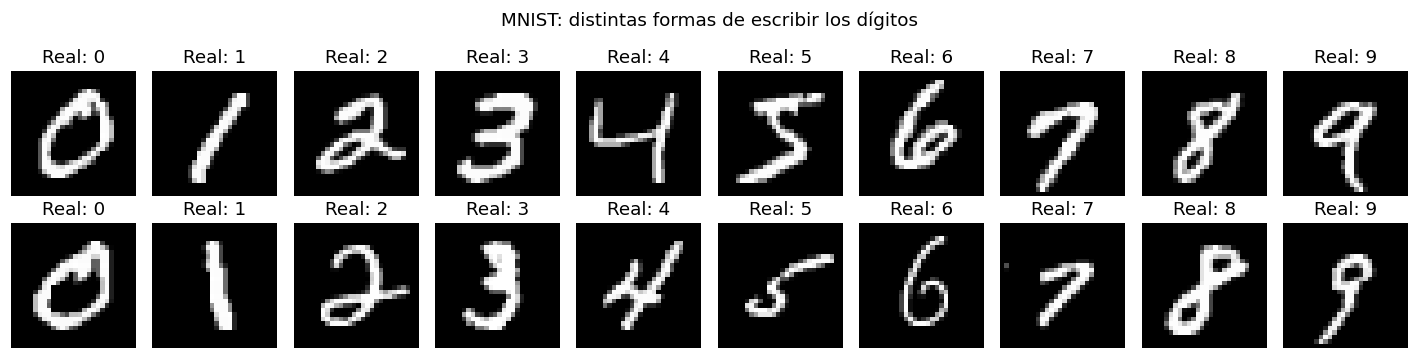

In [3]:
fig, ejes = plt.subplots(2, 10, figsize=(13, 3.4))
for digito in range(10):
    indices = np.flatnonzero(y_desarrollo == digito)[:2]
    for fila, indice in enumerate(indices):
        ejes[fila, digito].imshow(X_desarrollo_original[indice], cmap="gray")
        ejes[fila, digito].set_title(f"Real: {digito}")
        ejes[fila, digito].axis("off")
fig.suptitle("MNIST: distintas formas de escribir los dígitos")
plt.tight_layout()
plt.show()

**Pregunta 1.** ¿Cuántas variables de entrada obtenemos al convertir una imagen de 28 × 28 en un vector? ¿Por qué este problema es de clasificación y no de regresión?

**Respuesta:**

## 4. Separar los datos y normalizar las imágenes

De las 60 000 imágenes de desarrollo reservaremos 10 000 para validación. La prueba original permanece separada.

| Grupo | Imágenes | Uso |
|---|---:|---|
| Entrenamiento | 50 000 | Ajustar los pesos y los sesgos. |
| Validación | 10 000 | Observar la generalización y decidir cuándo detener el entrenamiento. |
| Prueba | 10 000 | Evaluar el modelo de referencia al final. |

`stratify` mantiene aproximadamente la proporción de las clases. Dividiremos las intensidades entre **255** para llevarlas al intervalo **[0, 1]** y usaremos `float32`. Esta transformación usa un límite conocido del formato; no calcula estadísticas con la prueba.

**Las etiquetas se conservan como enteros de 0 a 9.** No las dividimos entre 255.

In [4]:
X_ent_original, X_val_original, y_ent, y_val = train_test_split(
    X_desarrollo_original, y_desarrollo,
    test_size=10000, stratify=y_desarrollo, random_state=SEMILLA
)
X_ent = X_ent_original.astype("float32") / 255.0
X_val = X_val_original.astype("float32") / 255.0
X_prueba = X_prueba_original.astype("float32") / 255.0

particiones = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Imágenes": [len(X_ent), len(X_val), len(X_prueba)]
})
display(particiones)
print("Rango normalizado de entrenamiento:", X_ent.min(), "a", X_ent.max())
print("Una imagen:", X_ent[0].shape, "→", X_ent[0].size, "entradas")

,Conjunto,Imágenes
0,Entrenamiento,50000
1,Validación,10000
2,Prueba,10000


Rango normalizado de entrenamiento: 0.0 a 1.0
Una imagen: (28, 28) → 784 entradas


**Pregunta 2.** ¿Qué conjunto modifica los pesos de la red? ¿Cuál permite vigilar el sobreajuste? ¿Por qué no debemos ajustar los hiperparámetros mirando los resultados de prueba?

**Respuesta:**

## 5. ¿Qué aprenderá la red neuronal?

Una neurona recibe entradas, calcula una **agregación** y aplica una **activación**:

$$z = \sum_{i=1}^{n} w_i x_i + b, \qquad a = f(z).$$

- **Pesos ($w_i$):** determinan cómo contribuye cada entrada a la agregación.
- **Sesgo o bias ($b$):** desplaza el valor de esa agregación.
- **ReLU:** devuelve $\max(0,z)$; será la activación de la capa oculta.
- **Softmax:** transforma las diez salidas en probabilidades que suman aproximadamente 1.

Los pesos y los sesgos son **parámetros aprendidos**. La cantidad de neuronas, las épocas y la tasa de aprendizaje son **hiperparámetros que configuramos**.

Nuestra primera red tendrá esta estructura:

| Capa | Función | Salida por imagen |
|---|---|---|
| `Input` | Recibir la imagen. | 28 × 28 |
| `Flatten` | Reorganizar los píxeles; no aprende pesos. | 784 valores |
| `Dense(128, relu)` | Aprender combinaciones de los píxeles. | 128 activaciones |
| `Dense(10, softmax)` | Asignar una probabilidad a cada dígito. | 10 probabilidades |

Si la mayor probabilidad está en la posición 7, la clase predicha será **7**. Usaremos una red densa para concentrarnos en los conceptos básicos; no necesitamos una red convolucional para este primer ejercicio.

## 6. Definir los hiperparámetros y construir el modelo

| Hiperparámetro | Valor inicial | ¿Qué controla? |
|---|---:|---|
| Neuronas ocultas | 128 | Capacidad de representación de la capa. |
| Capas ocultas | 1 | Profundidad de la red. |
| Activación oculta | ReLU | Transformación no lineal de cada neurona. |
| Tasa de aprendizaje | 0.001 | Escala de los cambios de los parámetros. |
| Optimizador | Adam | Regla utilizada para actualizar los parámetros. |
| Épocas máximas | 10 | Máximo de recorridos completos por el entrenamiento. |
| Tamaño del lote | 128 | Imágenes procesadas antes de cada actualización. |
| Paciencia | 2 | Épocas sin mejorar la pérdida de validación antes de parar. |

Una **época** no es una sola actualización: contiene varios lotes. Con 50 000 imágenes y lotes de 128, habrá **391 actualizaciones por época**, incluido el último lote incompleto.

Las **10 neuronas de salida** corresponden a las diez clases del problema. No se cambia esa cantidad como si fuera el número de neuronas ocultas.

In [5]:
NEURONAS = 128
TASA_APRENDIZAJE = 0.001
EPOCAS = 10
LOTE = 128
PACIENCIA = 2
keras.utils.set_random_seed(SEMILLA)
modelo = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(NEURONAS, activation="relu", name="oculta"),
    keras.layers.Dense(10, activation="softmax", name="salida")
], name="clasificador_mnist")
modelo.summary()
print("Lotes por época:", int(np.ceil(len(X_ent) / LOTE)))
pesos_antes, sesgos_antes = modelo.get_layer("oculta").get_weights()
print("Matriz de pesos de la capa oculta:", pesos_antes.shape)
print("Sesgos de la capa oculta:", sesgos_antes.shape)

Model: "clasificador_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta (Dense)                  │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Lotes por época: 391
Matriz de pesos de la capa oculta: (784, 128)
Sesgos de la capa oculta: (128,)


**Pregunta 3.** ¿Qué diferencia hay entre los 128 valores de sesgo y el hiperparámetro `NEURONAS = 128`? ¿Cuántas conexiones con pesos tiene la primera capa densa, sin contar los sesgos?

**Respuesta:**

## 7. Compilar y entrenar el modelo de referencia

`compile()` define cómo aprenderá la red; `fit()` ejecuta el entrenamiento.

En cada lote ocurre lo siguiente:
1. **Propagación hacia adelante (forward):** la red obtiene las probabilidades de cada clase.
2. **Pérdida:** compara esas probabilidades con las etiquetas reales.
3. **Retropropagación (backward):** calcula los gradientes de la pérdida respecto a los parámetros.
4. **Actualización:** el optimizador modifica los pesos y sesgos.

La regla básica del descenso de gradiente es:

$$w_{\text{nuevo}} = w_{\text{anterior}} - \eta\,\frac{\partial L}{\partial w}.$$

$\eta$ es la tasa de aprendizaje y $L$ la pérdida. **Adam**, utilizado aquí, adapta la actualización mediante estimaciones de los gradientes; la ecuación anterior muestra la idea del descenso de gradiente simple.

Usaremos dos medidas distintas:
- **`loss`:** entropía cruzada; penaliza las probabilidades asignadas a las clases reales. Menor es mejor. `sparse_categorical_crossentropy` acepta etiquetas enteras.
- **`accuracy`:** exactitud, la proporción de imágenes clasificadas correctamente. Mayor es mejor. No es la métrica *precision*.

`EarlyStopping` observa `val_loss`, detiene el entrenamiento si no mejora durante dos épocas y **restaura los pesos de la mejor época de validación**. La validación no participa en el cálculo de gradientes.

In [6]:
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=TASA_APRENDIZAJE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
parada = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=PACIENCIA, restore_best_weights=True
)
historial = modelo.fit(
    X_ent, y_ent,
    validation_data=(X_val, y_val),
    epochs=EPOCAS, batch_size=LOTE,
    callbacks=[parada], shuffle=True, verbose=2
)
pesos_despues, sesgos_despues = modelo.get_layer("oculta").get_weights()
print("Cambio absoluto promedio de los pesos:",
      float(np.mean(np.abs(pesos_despues - pesos_antes))))
print("Cambio absoluto promedio de los sesgos:",
      float(np.mean(np.abs(sesgos_despues - sesgos_antes))))

Epoch 1/10
391/391 - 3s - 7ms/step - accuracy: 0.8953 - loss: 0.3821 - val_accuracy: 0.9396 - val_loss: 0.2170
Epoch 2/10
391/391 - 2s - 5ms/step - accuracy: 0.9503 - loss: 0.1743 - val_accuracy: 0.9552 - val_loss: 0.1576
Epoch 3/10
391/391 - 3s - 9ms/step - accuracy: 0.9641 - loss: 0.1258 - val_accuracy: 0.9627 - val_loss: 0.1291
Epoch 4/10
391/391 - 1s - 3ms/step - accuracy: 0.9724 - loss: 0.0980 - val_accuracy: 0.9678 - val_loss: 0.1140
Epoch 5/10
391/391 - 1s - 3ms/step - accuracy: 0.9775 - loss: 0.0795 - val_accuracy: 0.9704 - val_loss: 0.1048
Epoch 6/10
391/391 - 1s - 3ms/step - accuracy: 0.9822 - loss: 0.0657 - val_accuracy: 0.9719 - val_loss: 0.0989
Epoch 7/10
391/391 - 1s - 3ms/step - accuracy: 0.9852 - loss: 0.0550 - val_accuracy: 0.9729 - val_loss: 0.0952
Epoch 8/10
391/391 - 1s - 3ms/step - accuracy: 0.9879 - loss: 0.0462 - val_accuracy: 0.9738 - val_loss: 0.0924
Epoch 9/10
391/391 - 1s - 3ms/step - accuracy: 0.9899 - loss: 0.0391 - val_accuracy: 0.9747 - val_loss: 0.0904
E

## 8. Leer las curvas de aprendizaje

Graficaremos la **pérdida** y la **exactitud** por época, tanto en entrenamiento como en validación. La línea vertical marca la época con menor pérdida de validación.

La función siguiente solo dibuja los resultados registrados: **no inventa curvas ni valores**. La reutilizaremos para los otros modelos.

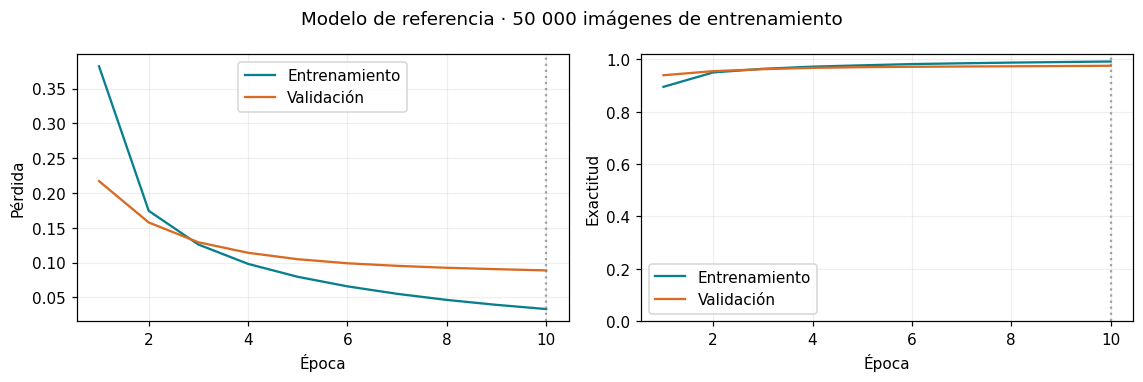

Época con menor pérdida de validación: 10


In [7]:
def graficar_historial(historial, titulo):
    h = historial.history
    epocas = np.arange(1, len(h["loss"]) + 1)
    mejor_epoca = int(np.argmin(h["val_loss"]) + 1)
    fig, ejes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    for eje, metrica, etiqueta in zip(
        ejes, ["loss", "accuracy"], ["Pérdida", "Exactitud"]
    ):
        eje.plot(epocas, h[metrica], color="#087f8c", label="Entrenamiento")
        eje.plot(epocas, h["val_" + metrica], color="#d96a22", label="Validación")
        eje.axvline(mejor_epoca, color="gray", linestyle=":", alpha=0.7)
        eje.set(xlabel="Época", ylabel=etiqueta)
        if metrica == "accuracy":
            eje.set_ylim(0, 1.02)
        eje.grid(alpha=0.2)
        eje.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()
    print("Época con menor pérdida de validación:", mejor_epoca)

graficar_historial(historial, "Modelo de referencia · 50 000 imágenes de entrenamiento")

**Pregunta 4.** ¿Disminuye la pérdida de entrenamiento? ¿La pérdida de validación también disminuye durante todas las épocas? ¿La última época coincide con la mejor? Justifica con la gráfica.

**Respuesta:**

> Una pequeña diferencia entre entrenamiento y validación es habitual. Si la pérdida de entrenamiento sigue bajando mientras la de validación aumenta de forma sostenida, hay evidencia de sobreajuste. La exactitud puede permanecer casi igual mientras la pérdida aumenta por errores cada vez más confiados.

## 9. Ejemplo de subajuste

Hay **subajuste** cuando el modelo no aprende suficientemente los patrones del entrenamiento y también tiene un desempeño bajo en validación. Puede deberse a capacidad insuficiente, entrenamiento insuficiente o una configuración que dificulte el aprendizaje.

Para hacer experimentos rápidos seleccionaremos **1 000 imágenes de entrenamiento y 2 000 de validación**, manteniendo las clases representadas. Los tres modelos de los apartados 9–11 usarán exactamente estos mismos subconjuntos.

La primera configuración tendrá **8 neuronas**, una tasa pequeña de **0.0001** y solo **5 épocas**. Combinamos varias restricciones para mostrar un caso de aprendizaje insuficiente; esto no aísla el efecto de una sola variable ni demuestra que toda red pequeña subajuste.

Entrenamiento para los ejemplos: 1000
Validación para los ejemplos: 2000


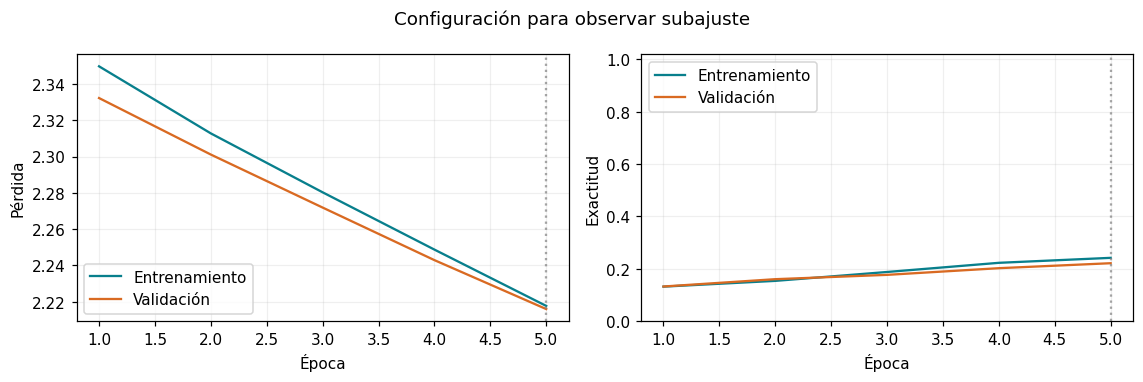

Época con menor pérdida de validación: 5


In [8]:
X_demo, _, y_demo, _ = train_test_split(
    X_ent, y_ent, train_size=1000, stratify=y_ent, random_state=SEMILLA
)
X_val_demo, _, y_val_demo, _ = train_test_split(
    X_val, y_val, train_size=2000, stratify=y_val, random_state=SEMILLA
)
print("Entrenamiento para los ejemplos:", len(X_demo))
print("Validación para los ejemplos:", len(X_val_demo))

keras.utils.set_random_seed(SEMILLA)
modelo_sub = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
modelo_sub.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
hist_sub = modelo_sub.fit(
    X_demo, y_demo, validation_data=(X_val_demo, y_val_demo),
    epochs=5, batch_size=64, shuffle=True, verbose=0
)
graficar_historial(hist_sub, "Configuración para observar subajuste")

**Pregunta 5.** ¿El modelo funciona bien sobre los propios datos con los que aprendió? ¿Una brecha pequeña entre entrenamiento y validación garantiza un buen modelo? Explica con este resultado.

**Respuesta:**

## 10. Ejemplo de sobreajuste

Hay **sobreajuste** cuando el modelo aprende particularidades del entrenamiento que no se trasladan bien a datos nuevos. Puede alcanzar una exactitud de entrenamiento muy alta sin conseguir un resultado comparable en validación.

Ahora usaremos **dos capas ocultas de 512 y 256 neuronas**, sin Dropout, durante **50 épocas**, con las mismas 1 000 imágenes. Esta combinación de alta capacidad, pocos ejemplos y entrenamiento prolongado favorece el sobreajuste.

**No aplicaremos parada temprana en este ejemplo**, para observar qué sucede después de la mejor época. Busca la separación de las curvas y el comportamiento de `val_loss`; una exactitud de entrenamiento cercana al 100 % no basta por sí sola para concluir que hay sobreajuste.

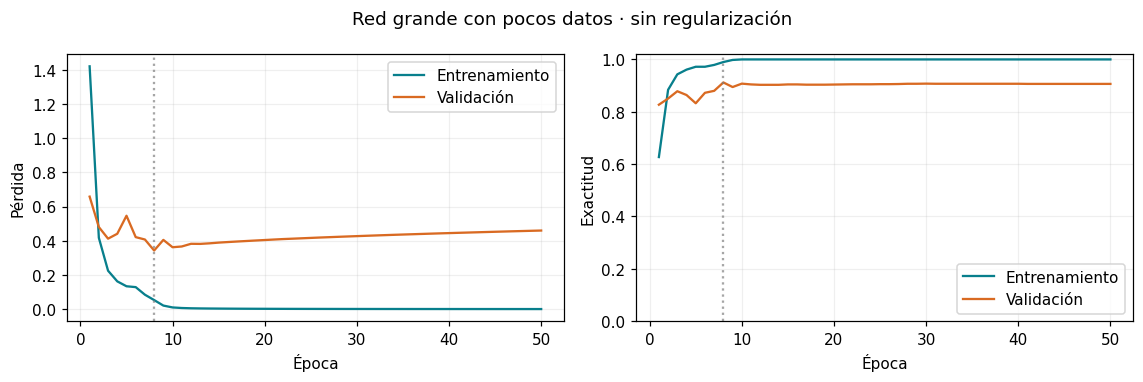

Época con menor pérdida de validación: 8


In [9]:
keras.utils.set_random_seed(SEMILLA)
modelo_sobre = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
modelo_sobre.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
hist_sobre = modelo_sobre.fit(
    X_demo, y_demo, validation_data=(X_val_demo, y_val_demo),
    epochs=50, batch_size=64, shuffle=True, verbose=0
)
graficar_historial(hist_sobre, "Red grande con pocos datos · sin regularización")

**Pregunta 6.** ¿Después de qué época deja de mejorar la pérdida de validación? ¿Qué sucede al mismo tiempo con la pérdida de entrenamiento? ¿Conservarías necesariamente los pesos de la época 50?

**Respuesta:**

## 11. Intentar reducir el sobreajuste

Mantendremos las mismas imágenes, capas densas, tasa de aprendizaje y tamaño de lote del apartado anterior. Incorporaremos dos estrategias:

- **Dropout(0.5):** durante el entrenamiento anula aleatoriamente el 50 % de las activaciones de la capa anterior en cada paso y reescala las restantes. Favorece que la red no dependa siempre de las mismas activaciones. En evaluación y predicción se desactiva.
- **EarlyStopping:** detiene el entrenamiento después de cinco épocas sin mejorar `val_loss` y restaura los pesos de su mejor época.

No estamos eliminando permanentemente la mitad de las neuronas. Tampoco hay garantía de mejora: comprobaremos el efecto con la validación.

Al cambiar dos estrategias juntas, evaluamos su **efecto combinado**. Para separar sus efectos habría que probar cada una por separado.

> En estas curvas, la validación puede verse mejor que el entrenamiento al inicio: Dropout se aplica solo durante el entrenamiento. Además, la métrica de entrenamiento promedia lotes mientras los pesos cambian; la validación se calcula al terminar la época.

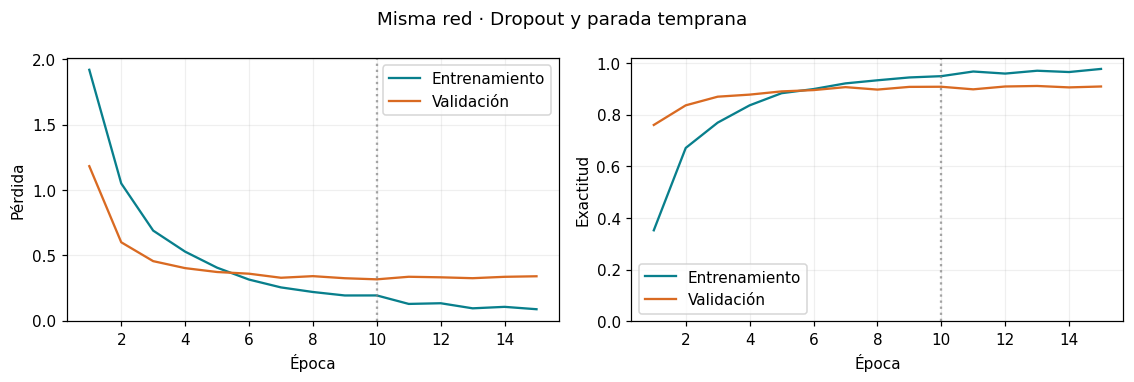

Época con menor pérdida de validación: 10


In [10]:
keras.utils.set_random_seed(SEMILLA)
modelo_regularizado = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(10, activation="softmax")
])
modelo_regularizado.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
parada_demo = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
hist_regularizado = modelo_regularizado.fit(
    X_demo, y_demo, validation_data=(X_val_demo, y_val_demo),
    epochs=50, batch_size=64, shuffle=True,
    callbacks=[parada_demo], verbose=0
)
graficar_historial(hist_regularizado, "Misma red · Dropout y parada temprana")

## 12. Comparar los tres ejemplos con los mismos datos

Reevaluaremos cada modelo después de entrenar. Esto permite comparar los conjuntos con **Dropout desactivado** y, en el modelo regularizado, con los **pesos restaurados**. Por eso la tabla puede diferir de la última fila del historial.

La brecha se calcula como **exactitud de entrenamiento menos exactitud de validación**, en **puntos porcentuales (pp)**. Una brecha pequeña solo es útil si el desempeño también es adecuado.

El modelo de referencia usa 50 000 imágenes y queda fuera de esta tabla: aquí los tres modelos tienen las mismas 1 000 imágenes de entrenamiento y 2 000 de validación.

,Modelo,Parámetros,Épocas ejecutadas,Época de los pesos evaluados,Exactitud ent. (%),Exactitud val. (%),Brecha (pp),Pérdida ent.,Pérdida val.
0,Configuración de subajuste,6370,5,5,25.1,22.15,2.95,2.2012,2.2160
1,Red grande sin regularizar,535818,50,50,100.0,90.65,9.35,0.0003,0.4598
2,Red grande regularizada,535818,15,10,99.3,90.80,8.50,0.0493,0.3160


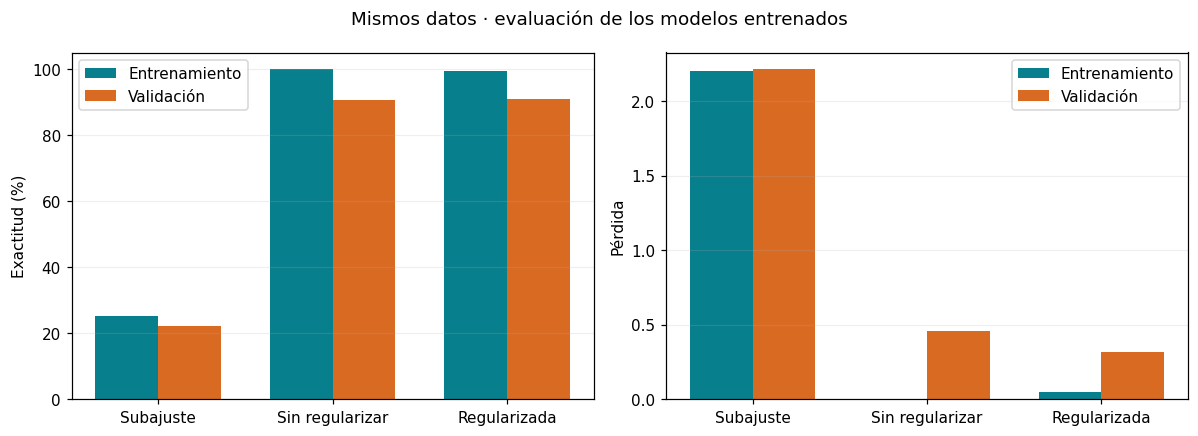

In [11]:
experimentos = [
    ("Configuración de subajuste", modelo_sub, hist_sub),
    ("Red grande sin regularizar", modelo_sobre, hist_sobre),
    ("Red grande regularizada", modelo_regularizado, hist_regularizado)
]
resultados = []
for nombre, red, historia in experimentos:
    ent = red.evaluate(X_demo, y_demo, verbose=0, return_dict=True)
    val = red.evaluate(X_val_demo, y_val_demo, verbose=0, return_dict=True)
    resultados.append({
        "Modelo": nombre,
        "Parámetros": red.count_params(),
        "Épocas ejecutadas": len(historia.history["loss"]),
        "Época de los pesos evaluados": (
            int(np.argmin(historia.history["val_loss"]) + 1)
            if red is modelo_regularizado else len(historia.history["loss"])
        ),
        "Exactitud ent. (%)": 100 * ent["accuracy"],
        "Exactitud val. (%)": 100 * val["accuracy"],
        "Brecha (pp)": 100 * (ent["accuracy"] - val["accuracy"]),
        "Pérdida ent.": ent["loss"],
        "Pérdida val.": val["loss"]
    })
comparacion = pd.DataFrame(resultados)
display(comparacion.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
etiquetas = ["Subajuste", "Sin regularizar", "Regularizada"]
x = np.arange(len(etiquetas))
for eje, columnas, ylabel in [
    (ejes[0], ["Exactitud ent. (%)", "Exactitud val. (%)"], "Exactitud (%)"),
    (ejes[1], ["Pérdida ent.", "Pérdida val."], "Pérdida")
]:
    eje.bar(x - 0.18, comparacion[columnas[0]], 0.36,
            label="Entrenamiento", color="#087f8c")
    eje.bar(x + 0.18, comparacion[columnas[1]], 0.36,
            label="Validación", color="#d96a22")
    eje.set_xticks(x, etiquetas)
    eje.set_ylabel(ylabel)
    eje.legend()
    eje.grid(axis="y", alpha=0.2)
ejes[0].set_ylim(0, 105)
fig.suptitle("Mismos datos · evaluación de los modelos entrenados")
plt.tight_layout()
plt.show()

**Pregunta 7.** Completa la tabla a partir de tus resultados. Si la regularización no mejora alguna métrica, indícalo: no tienes que forzar la conclusión esperada.

| Configuración | Evidencia en entrenamiento | Evidencia en validación | Interpretación |
|---|---|---|---|
| Subajuste | | | |
| Red grande sin regularizar | | | |
| Red grande regularizada | | | |

**¿Qué cambió al introducir Dropout y parada temprana?** Compara la pérdida de validación, la exactitud y la brecha; no elijas un modelo solo por tener la brecha más pequeña.

**Respuesta:**

> Las métricas pueden variar ligeramente entre equipos y versiones. Las conclusiones deben apoyarse en las curvas y tablas que produzca tu ejecución.

## 13. Experimento de hiperparámetros: cambiar solo la tasa de aprendizaje

Entrenaremos tres redes nuevas con **128 neuronas**, el mismo conjunto reducido, **6 épocas** y lotes de **64**. Solo cambiará la tasa de aprendizaje: `0.0001`, `0.001` y `0.01`.

Reiniciamos la semilla antes de construir cada red para igualar su inicialización. La comparación usa la pérdida de validación **después del mismo número de épocas**. Es una comparación con presupuesto fijo: una tasa pequeña podría necesitar más épocas.

Este es un experimento didáctico sobre 1 000 imágenes, no una búsqueda exhaustiva. La tasa ganadora aquí no tiene por qué ser la mejor con más datos o con otra arquitectura. El modelo de referencia del apartado 7 conserva su configuración original para la evaluación final.

,Tasa,Pérdida val. al terminar,Exactitud val. (%)
1,0.0010,0.4087,88.95
2,0.0100,0.4220,89.00
0,0.0001,1.5095,70.20


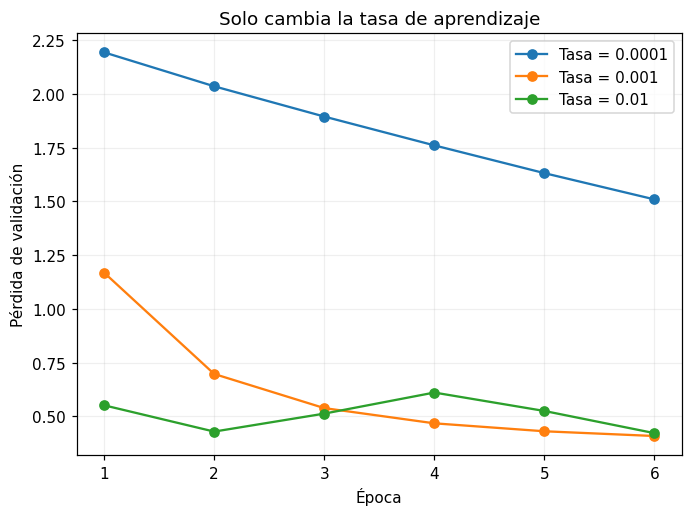

In [12]:
tasas = [0.0001, 0.001, 0.01]
filas_tasas = []
historias_tasas = {}

for tasa in tasas:
    keras.utils.set_random_seed(SEMILLA)
    modelo_tasa = keras.Sequential([
        keras.layers.Input(shape=(28, 28)),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(10, activation="softmax")
    ])
    modelo_tasa.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"]
    )
    h = modelo_tasa.fit(
        X_demo, y_demo, validation_data=(X_val_demo, y_val_demo),
        epochs=6, batch_size=64, shuffle=True, verbose=0
    )
    historias_tasas[tasa] = h.history
    resultado = modelo_tasa.evaluate(
        X_val_demo, y_val_demo, verbose=0, return_dict=True
    )
    filas_tasas.append({
        "Tasa": tasa,
        "Pérdida val. al terminar": resultado["loss"],
        "Exactitud val. (%)": 100 * resultado["accuracy"]
    })

tabla_tasas = pd.DataFrame(filas_tasas).sort_values("Pérdida val. al terminar")
display(tabla_tasas.round(4))
for tasa, h in historias_tasas.items():
    plt.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"],
             marker="o", label=f"Tasa = {tasa}")
plt.xlabel("Época")
plt.ylabel("Pérdida de validación")
plt.title("Solo cambia la tasa de aprendizaje")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Pregunta 8.** ¿Qué tasa obtuvo la menor pérdida al terminar las seis épocas? ¿Cuál aprendió más lentamente? ¿Podemos concluir que la mayor tasa siempre es mejor? Si ahora quisieras estudiar `batch_size`, ¿qué mantendrías constante?

**Respuesta:**

## 14. Evaluar el modelo de referencia en la prueba reservada

Volvemos a **`modelo`**, la red de 128 neuronas entrenada con 50 000 imágenes en el apartado 7. Conserva los pesos de su mejor época de validación. Los experimentos posteriores utilizaron otras variables y no modificaron sus pesos.

Ahora evaluamos las **10 000 imágenes de prueba**. Ya están fijados la arquitectura, los hiperparámetros y la época seleccionada. Las visualizaciones siguientes describen esta misma evaluación; no utilizaremos sus resultados para volver a ajustar el modelo.

In [13]:
resultado_prueba = modelo.evaluate(
    X_prueba, y_prueba, verbose=0, return_dict=True
)
print(f"Pérdida de prueba: {resultado_prueba['loss']:.4f}")
print(f"Exactitud de prueba: {100 * resultado_prueba['accuracy']:.2f} %")

probabilidades = modelo.predict(X_prueba, verbose=0)
predicciones = np.argmax(probabilidades, axis=1)
print("Predicciones correctas:", np.sum(predicciones == y_prueba), "de", len(y_prueba))

Pérdida de prueba: 0.0816
Exactitud de prueba: 97.64 %
Predicciones correctas: 9764 de 10000


## 15. Interpretar las predicciones y sus probabilidades

`predict()` devuelve diez probabilidades por imagen. `argmax()` devuelve la posición de la mayor probabilidad, que aquí coincide con el dígito predicho.

En el panel izquierdo veremos una imagen de prueba; en el derecho, sus diez probabilidades. **Una probabilidad alta no garantiza que la predicción sea correcta.** Estas probabilidades tampoco garantizan calibración perfecta.

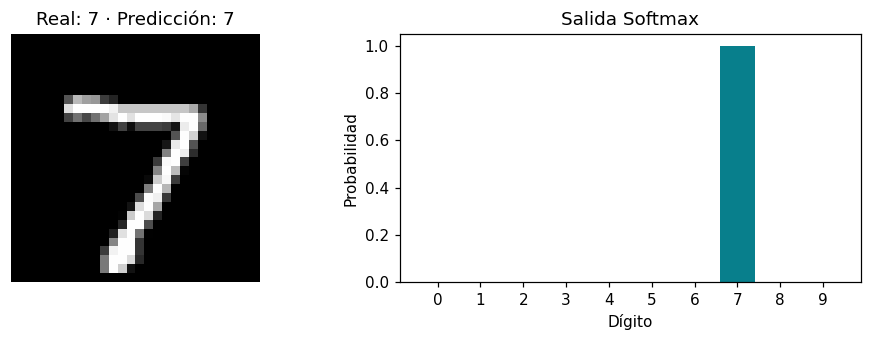

Suma de probabilidades: 0.9999999403953552


In [14]:
indice = 0  # Cambia este índice para observar otra imagen de prueba.
clase_predicha = int(predicciones[indice])
fig, ejes = plt.subplots(1, 2, figsize=(9, 3.2))
ejes[0].imshow(X_prueba[indice], cmap="gray")
ejes[0].set_title(f"Real: {y_prueba[indice]} · Predicción: {clase_predicha}")
ejes[0].axis("off")
colores = ["#087f8c" if d == clase_predicha else "#cbd5e1" for d in range(10)]
ejes[1].bar(range(10), probabilidades[indice], color=colores)
ejes[1].set(xticks=range(10), xlabel="Dígito", ylabel="Probabilidad", ylim=(0, 1.05))
ejes[1].set_title("Salida Softmax")
plt.tight_layout()
plt.show()
print("Suma de probabilidades:", float(probabilidades[indice].sum()))

Veamos varias predicciones. El título será verde si la clase es correcta y rojo si es incorrecta. Después mostraremos únicamente errores, si los hay, para inspeccionar qué dígitos resultaron difíciles.

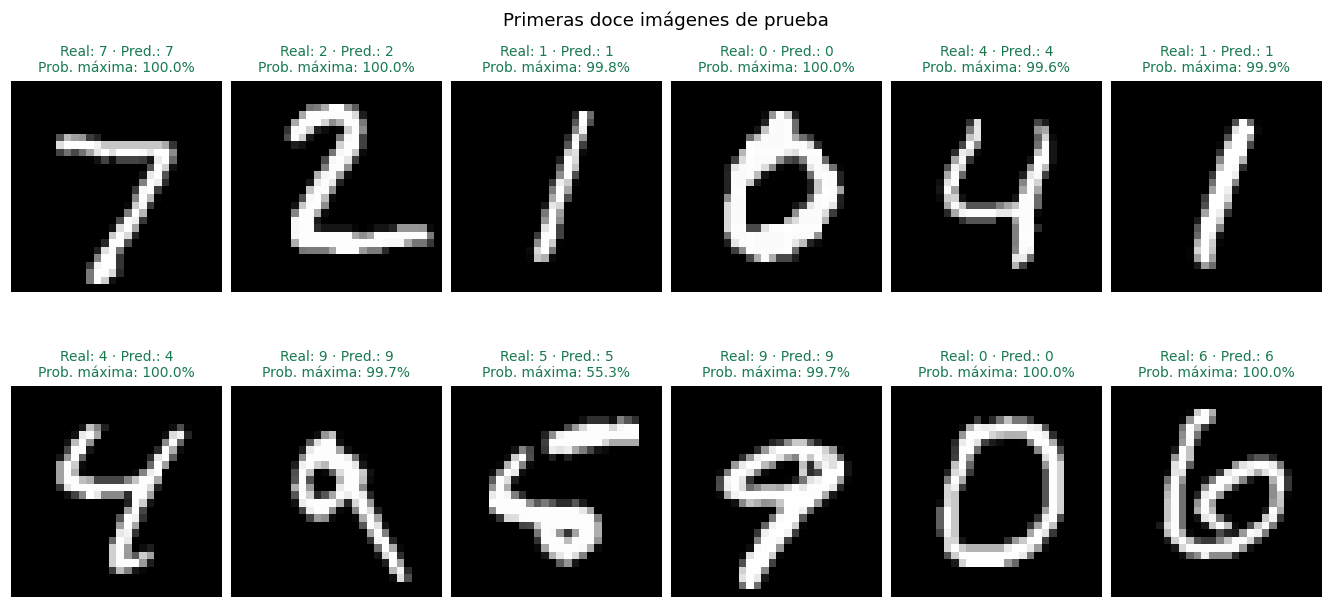

Total de errores: 236


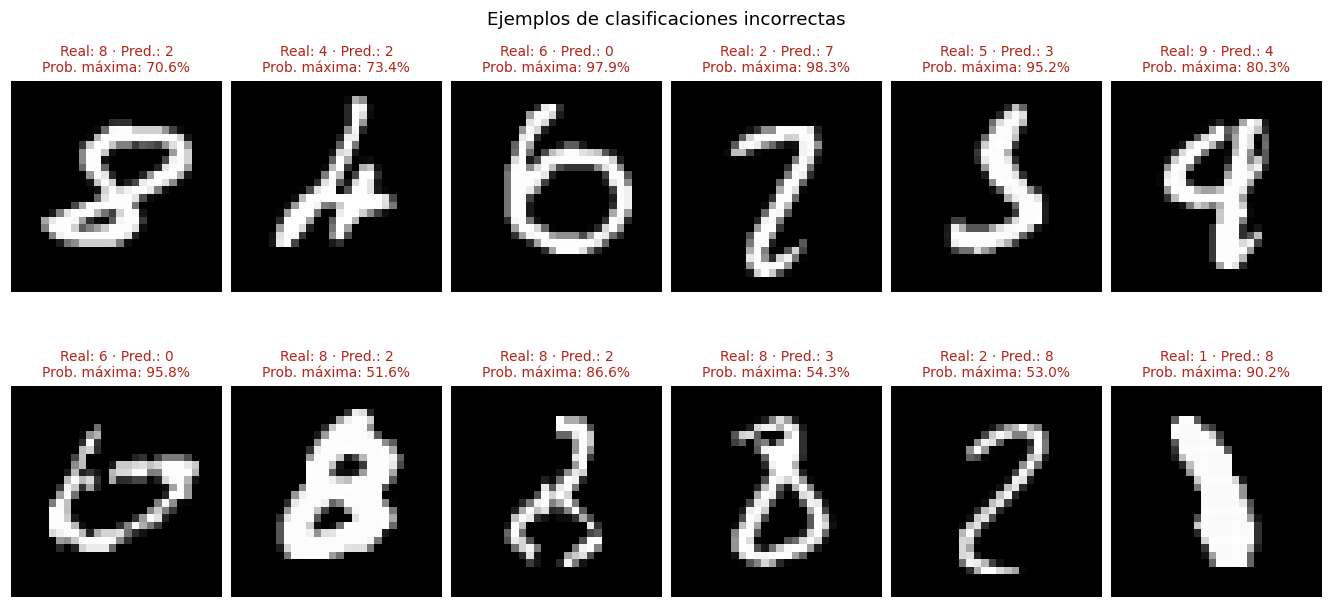

In [15]:
def mostrar_predicciones(indices, titulo):
    indices = np.asarray(indices)[:12]
    if len(indices) == 0:
        print("No hay imágenes para mostrar.")
        return
    filas = int(np.ceil(len(indices) / 6))
    fig, ejes = plt.subplots(filas, 6, figsize=(12, 2.9 * filas), squeeze=False, layout="constrained")
    for eje in ejes.ravel():
        eje.axis("off")
    for eje, i in zip(ejes.ravel(), indices):
        acierto = predicciones[i] == y_prueba[i]
        eje.imshow(X_prueba[i], cmap="gray")
        eje.set_title(
            f"Real: {y_prueba[i]} · Pred.: {predicciones[i]}\n"
            f"Prob. máxima: {probabilidades[i].max():.1%}",
            color="#18794e" if acierto else "#b42318", fontsize=9
        )
    fig.suptitle(titulo)
    plt.show()

mostrar_predicciones(np.arange(12), "Primeras doce imágenes de prueba")
indices_error = np.flatnonzero(predicciones != y_prueba)
print("Total de errores:", len(indices_error))
mostrar_predicciones(indices_error[:12], "Ejemplos de clasificaciones incorrectas")

## 16. Construir la matriz de confusión

Las **filas** representan las clases reales y las **columnas** las predichas. La diagonal reúne los aciertos; las otras celdas indican las confusiones.

Por ejemplo, la celda de la fila 4 y la columna 9 cuenta cuántos **4 reales fueron clasificados como 9**. Observaremos conteos, no porcentajes; el número de imágenes de prueba puede variar entre clases.

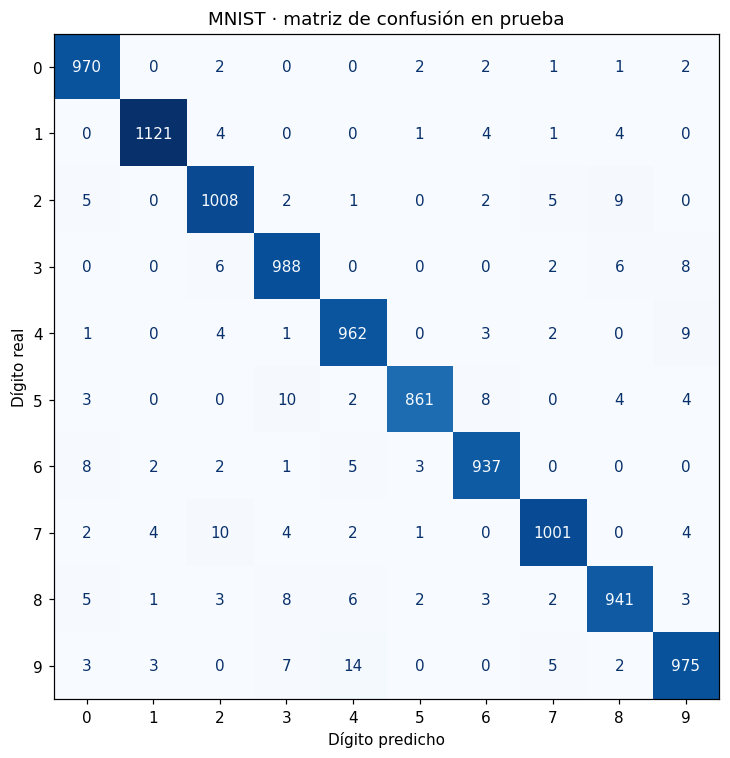

,Dígito real,Predicho,Cantidad
58,9,4,14
41,7,2,10
28,5,3,10
16,2,8,9
26,4,9,9


In [16]:
matriz = confusion_matrix(y_prueba, predicciones, labels=np.arange(10))
fig, eje = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(matriz, display_labels=np.arange(10)).plot(
    ax=eje, cmap="Blues", colorbar=False, values_format="d"
)
eje.set_title("MNIST · matriz de confusión en prueba")
eje.set_xlabel("Dígito predicho")
eje.set_ylabel("Dígito real")
plt.tight_layout()
plt.show()

confusiones = pd.DataFrame([
    {"Dígito real": real, "Predicho": pred, "Cantidad": int(matriz[real, pred])}
    for real in range(10) for pred in range(10)
    if real != pred and matriz[real, pred] > 0
]).reindex(columns=["Dígito real", "Predicho", "Cantidad"])
display(confusiones.sort_values("Cantidad", ascending=False).head(5))

**Pregunta 9.** ¿Cuál fue la confusión más frecuente en cantidad de imágenes? Examina los ejemplos incorrectos: ¿alguno recibió una probabilidad alta? ¿Qué nos enseña eso sobre la confianza del modelo?

**Respuesta:**

## 17. Preguntas finales y conclusión

1. ¿Cuál fue la exactitud de prueba del modelo de referencia? Explica qué significa ese porcentaje.
2. Menciona **dos parámetros aprendidos** y **tres hiperparámetros** de una red neuronal.
3. ¿Qué diferencia observaste entre subajuste y sobreajuste? Cita al menos una medida o una tendencia de cada ejemplo.
4. ¿El modelo regularizado mejoró la pérdida de validación respecto a la red grande sin regularizar? ¿También mejoró su exactitud?
5. ¿Por qué no basta con alcanzar el 100 % de exactitud en entrenamiento? ¿Qué papel cumplen validación y prueba?
6. Escribe una conclusión de tres o cuatro líneas sobre lo aprendido y una modificación que evaluarías en un nuevo experimento, usando validación para tomar esa decisión.

**Respuestas:**

1.
2.
3.
4.
5.
6.

**Para interpretar:** ni una red más grande, ni más épocas, ni una tasa de aprendizaje mayor garantizan una mejora. El objetivo es generalizar a imágenes nuevas, y las decisiones se justifican con evidencia de validación. Esta práctica usa una sola partición y una semilla para mantener el procedimiento sencillo.

**Material de apoyo:**
- [MNIST: descripción y carga del dataset (Keras)](https://keras.io/api/datasets/mnist/).
- [Introducción a TensorFlow para principiantes](https://www.tensorflow.org/tutorials/quickstart/beginner).
- [Subajuste, sobreajuste y regularización (TensorFlow)](https://www.tensorflow.org/tutorials/keras/overfit_and_underfit).
- [EarlyStopping y restauración de pesos (Keras)](https://keras.io/api/callbacks/early_stopping/).

Los resultados incluidos se calculan al ejecutar las celdas. Las preguntas quedan abiertas para el estudiante.